In [1]:

import pandas as pd
import matplotlib.pyplot as plt

# Membaca dataset
df = pd.read_csv('/content/reviews.csv')

# Menampilkan ukuran dataset
print("Jumlah baris dan kolom:", df.shape)

# Menampilkan nama kolom
print("\nNama kolom:")
print(df.columns.tolist())

# Menampilkan 5 data pertama
df.head()


Jumlah baris dan kolom: (12495, 12)

Nama kolom:
['reviewId', 'userName', 'userImage', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'sortOrder', 'appId']


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,sortOrder,appId
0,gp:AOqpTOEhZuqSqqWnaKRgv-9ABYdajFUB0WugPGh-SG-...,Eric Tie,https://play-lh.googleusercontent.com/a-/AOh14...,I cannot open the app anymore,1,0,5.4.0.6,2020-10-27 21:24:41,NaN,NaN,newest,com.anydo
1,gp:AOqpTOH0WP4IQKBZ2LrdNmFy_YmpPCVrV3diEU9KGm3...,john alpha,https://play-lh.googleusercontent.com/a-/AOh14...,I have been begging for a refund from this app...,1,0,NaN,2020-10-27 14:03:28,"Please note that from checking our records, yo...",2020-10-27 15:05:52,newest,com.anydo
2,gp:AOqpTOEMCkJB8Iq1p-r9dPwnSYadA5BkPWTf32Z1azu...,Sudhakar .S,https://play-lh.googleusercontent.com/a-/AOh14...,Very costly for the premium version (approx In...,1,0,NaN,2020-10-27 08:18:40,NaN,NaN,newest,com.anydo
3,gp:AOqpTOGFrUWuKGycpje8kszj3uwHN6tU_fd4gLVFy9z...,SKGflorida@bellsouth.net DAVID S,https://play-lh.googleusercontent.com/-75aK0WF...,"Used to keep me organized, but all the 2020 UP...",1,0,NaN,2020-10-26 13:28:07,What do you find troublesome about the update?...,2020-10-26 14:58:29,newest,com.anydo
4,gp:AOqpTOHls7DW8wmDFzTkHwxuqFkdNQtKHmO6Pt9jhZE...,Louann Stoker,https://play-lh.googleusercontent.com/-pBcY_Z-...,Dan Birthday Oct 28,1,0,5.6.0.7,2020-10-26 06:10:50,NaN,NaN,newest,com.anydo


In [2]:

# Informasi dataset
df.info()

# Jumlah data kosong setiap kolom
print("\nData kosong:")
print(df.isnull().sum())

# Jumlah baris duplikat
print("\nJumlah baris duplikat:", df.duplicated().sum())

# Statistik rating
print("\nDistribusi rating:")
print(df['score'].value_counts().sort_index())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12495 entries, 0 to 12494
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   reviewId              12495 non-null  object
 1   userName              12495 non-null  object
 2   userImage             12495 non-null  object
 3   content               12495 non-null  object
 4   score                 12495 non-null  int64 
 5   thumbsUpCount         12495 non-null  int64 
 6   reviewCreatedVersion  10333 non-null  object
 7   at                    12495 non-null  object
 8   replyContent          5818 non-null   object
 9   repliedAt             5818 non-null   object
 10  sortOrder             12495 non-null  object
 11  appId                 12495 non-null  object
dtypes: int64(2), object(10)
memory usage: 1.1+ MB

Data kosong:
reviewId                   0
userName                   0
userImage                  0
content                    0
score     

In [3]:

# Menampilkan 10 contoh ulasan
for i, review in enumerate(df['content'].head(10), start=1):
    print(f"{i}. {review}")

# Memeriksa teks kosong
print("\nJumlah teks kosong:")
print(df['content'].isna().sum())

# Memeriksa teks yang hanya berisi spasi
print("\nJumlah teks kosong setelah menghapus spasi:")
print(df['content'].str.strip().eq('').sum())

# Memeriksa duplikasi berdasarkan isi ulasan
print("\nJumlah ulasan duplikat:")
print(df['content'].duplicated().sum())

# Melihat panjang teks ulasan
df['panjang_teks'] = df['content'].str.len()

print("\nStatistik panjang teks:")
print(df['panjang_teks'].describe())


1. I cannot open the app anymore
2. I have been begging for a refund from this app for over a month and nobody is replying me
3. Very costly for the premium version (approx Indian Rupees 910 per year). Better to download the premium version of this app from apkmos website and use it. Microsoft to do list app is far more better.
4. Used to keep me organized, but all the 2020 UPDATES have made a mess of things !!! Y cudn't u leave well enuf alone ??? Guess ur techies feel the need to keep making changes to justify continuing to collect their salary !!! 🤤🤤🤤
5. Dan Birthday Oct 28
6. It has changed how I viewed my different lists. Now they are all jumbled together and I can't find what I need.
7. I'm only looking for a grocery list app but every time I tap away from the app I have to tap again (after opening it again) to see the list. I can't find a way to keep a certain list showing when I open or reopen the app. eta: in response to the reply, it doesn't work like that on my phone. Even i

In [4]:

import re

# Menyalin data agar dataset asli tetap aman
df_clean = df.copy()

# Menghapus ulasan duplikat berdasarkan isi teks
df_clean = df_clean.drop_duplicates(subset='content').copy()

# Membersihkan teks
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_clean['cleaned_content'] = df_clean['content'].apply(clean_text)

# Menghapus teks yang kosong setelah dibersihkan
df_clean = df_clean[
    df_clean['cleaned_content'].str.strip() != ''
].copy()

# Menampilkan hasil
print("Jumlah data sebelum preprocessing:", len(df))
print("Jumlah data setelah preprocessing:", len(df_clean))
print("\nContoh teks sebelum dan sesudah dibersihkan:")

for _, row in df_clean[['content', 'cleaned_content']].head(5).iterrows():
    print("\nSebelum:", row['content'])
    print("Sesudah:", row['cleaned_content'])


Jumlah data sebelum preprocessing: 12495
Jumlah data setelah preprocessing: 11713

Contoh teks sebelum dan sesudah dibersihkan:

Sebelum: I cannot open the app anymore
Sesudah: i cannot open the app anymore

Sebelum: I have been begging for a refund from this app for over a month and nobody is replying me
Sesudah: i have been begging for a refund from this app for over a month and nobody is replying me

Sebelum: Very costly for the premium version (approx Indian Rupees 910 per year). Better to download the premium version of this app from apkmos website and use it. Microsoft to do list app is far more better.
Sesudah: very costly for the premium version approx indian rupees per year better to download the premium version of this app from apkmos website and use it microsoft to do list app is far more better

Sebelum: Used to keep me organized, but all the 2020 UPDATES have made a mess of things !!! Y cudn't u leave well enuf alone ??? Guess ur techies feel the need to keep making change

## Eksperimen 1 — TF-IDF konfigurasi A

Bagian ini adalah baseline TF-IDF. Hasilnya digunakan untuk perbandingan, bukan sebagai model final.

In [5]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Mengubah teks menjadi vektor TF-IDF
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=3000,
    min_df=5
)

X = tfidf.fit_transform(df_clean['cleaned_content'])

print("Ukuran matriks TF-IDF:", X.shape)


Ukuran matriks TF-IDF: (11713, 2776)


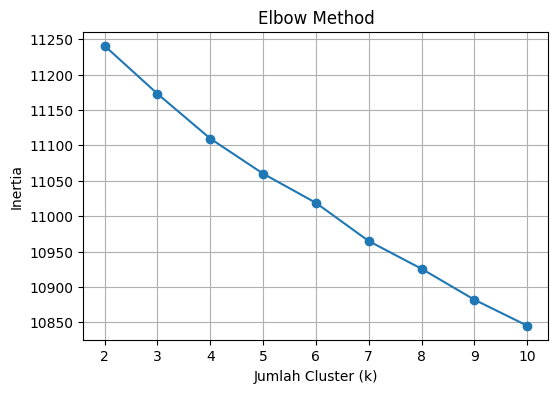

In [6]:

from sklearn.cluster import KMeans

inertia = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X)
    inertia.append(model.inertia_)

plt.figure(figsize=(6,4))
plt.plot(range(2,11), inertia, marker='o')
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()


Mengevaluasi k = 2...
Mengevaluasi k = 3...
Mengevaluasi k = 4...
Mengevaluasi k = 5...
Mengevaluasi k = 6...
Mengevaluasi k = 7...
Mengevaluasi k = 8...


,Jumlah Cluster,Inertia,Silhouette Score
0,2,11240.6807,0.0089
1,3,11172.8994,0.0087
2,4,11109.5924,0.0110
3,5,11060.0316,0.0116
4,6,11018.7873,0.0131
5,7,10964.8024,0.0138
6,8,10925.6433,0.0181


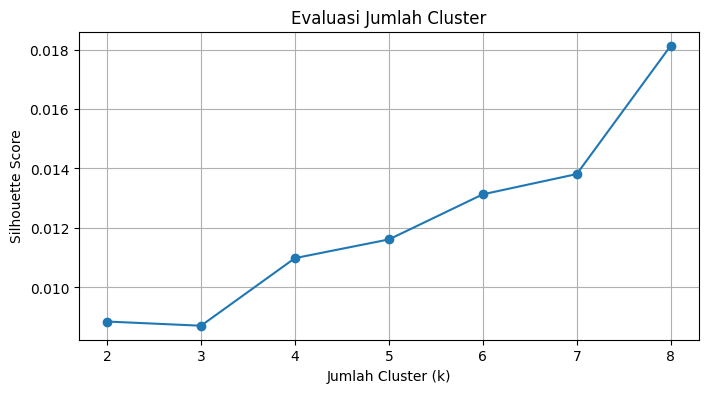

In [7]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

hasil_evaluasi = []

for k in range(2, 9):
    print(f"Mengevaluasi k = {k}...")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(
        X,
        labels,
        metric='cosine',
        sample_size=2000,
        random_state=42
    )

    hasil_evaluasi.append({
        'Jumlah Cluster': k,
        'Inertia': model.inertia_,
        'Silhouette Score': score
    })

evaluasi_df = pd.DataFrame(hasil_evaluasi)
display(evaluasi_df.round(4))

# Grafik Silhouette Score
plt.figure(figsize=(8, 4))
plt.plot(
    evaluasi_df['Jumlah Cluster'],
    evaluasi_df['Silhouette Score'],
    marker='o'
)
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Silhouette Score')
plt.title('Evaluasi Jumlah Cluster')
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()


In [8]:

from sklearn.cluster import KMeans

# Membuat model K-Means dengan 8 cluster
kmeans = KMeans(
    n_clusters=8,
    random_state=42,
    n_init=10
)

# Melatih model dan menentukan cluster setiap ulasan
df_clean['cluster'] = kmeans.fit_predict(X)

# Menampilkan jumlah ulasan di setiap cluster
print("Jumlah ulasan pada setiap cluster:")
print(df_clean['cluster'].value_counts().sort_index())

# Menampilkan beberapa contoh hasil clustering
display(
    df_clean[['content', 'score', 'cluster']]
    .sort_values('cluster')
    .groupby('cluster')
    .head(3)
    .sort_values('cluster')
)


Jumlah ulasan pada setiap cluster:
cluster
0    6607
1     468
2     549
3     390
4     667
5     266
6    2341
7     425
Name: count, dtype: int64


,content,score,cluster
4947,Synchronisation is not working. It's dishonest...,1,0
4960,Reminders are not on time!,2,0
4961,"Like others have said in here, the widget free...",2,0
4925,Like another commenter said. Just installed it...,1,1
1181,Almost no productivity without premium version.,2,1
5278,"Dont buy the premium, the widgets don't work (...",3,1
12384,Using it for couple of year now excellent app ...,5,2
7424,it would be great if we could have geographic ...,4,2
7414,"great app, loving the interaction with O365",4,2
12439,Easy to work out the app,5,3


In [9]:

# Gunakan vectorizer yang membentuk matriks X pada konfigurasi A.
terms = tfidf.get_feature_names_out()

order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

for i in range(8):
    print(f"\nCluster {i}:")
    top_terms = [
        terms[ind] for ind in order_centroids[i, :15]
    ]
    print(", ".join(top_terms))



Cluster 0:
tasks, like, app, time, task, calendar, work, just, day, add, don, doesn, list, widget, really

Cluster 1:
premium, app, features, version, feature, pay, bought, paid, sync, good, account, use, reminders, trees, really

Cluster 2:
great, app, really, love, tasks, use, far, track, tool, day, work, calendar, helps, works, time

Cluster 3:
easy, use, simple, app, helpful, good, useful, great, love, nice, track, interface, really, like, habits

Cluster 4:
version, free, pro, app, paid, buy, features, pay, trees, like, just, calendar, ads, habits, need

Cluster 5:
best, app, ve, used, list, apps, calendar, productivity, far, habit, tried, simple, todo, task, planner

Cluster 6:
app, love, nice, really, like, time, use, just, useful, phone, good, calendar, amazing, work, using

Cluster 7:
good, app, far, pretty, need, really, track, use, list, habits, apps, tasks, help, application, like


In [10]:

# Ringkasan setiap cluster
ringkasan = df_clean.groupby('cluster').agg(
    jumlah_ulasan=('content', 'count'),
    rata_rata_rating=('score', 'mean'),
    median_rating=('score', 'median')
).round(2)

display(ringkasan)

# Menampilkan 5 contoh ulasan dari setiap cluster
for i in sorted(df_clean['cluster'].unique()):
    print(f"\n{'='*20} CLUSTER {i} {'='*20}")

    contoh = df_clean[df_clean['cluster'] == i][
        ['content', 'score']
    ].head(5)

    for _, row in contoh.iterrows():
        print(f"Rating {row['score']}: {row['content']}\n")


,jumlah_ulasan,rata_rata_rating,median_rating
cluster,,,
0,6607,2.79,3.0
1,468,2.24,2.0
2,549,4.05,4.0
3,390,4.07,4.0
4,667,2.43,2.0
5,266,4.48,5.0
6,2341,3.32,4.0
7,425,3.85,4.0



==================== CLUSTER 0 ====================
Rating 1: I have been begging for a refund from this app for over a month and nobody is replying me

Rating 1: Used to keep me organized, but all the 2020 UPDATES have made a mess of things !!! Y cudn't u leave well enuf alone ??? Guess ur techies feel the need to keep making changes to justify continuing to collect their salary !!! 🤤🤤🤤

Rating 1: Dan Birthday Oct 28

Rating 1: It has changed how I viewed my different lists. Now they are all jumbled together and I can't find what I need.

Rating 1: I complain about not crashes and it was immediately fixed!Good job!! Now the crashes have returned! I really need it fixed because I need to change apps otherwise 😩 I followed your instructions on deleting the data, etc but it just now crashed again. I am a patient person and I have used Any Do for years but let's try one more time and then I will have to find another app. It crashed again 😑


==================== CLUSTER 1 ===============

## Eksperimen 2 — TF-IDF konfigurasi B

Bagian ini membandingkan TF-IDF unigram + bigram. Model 8 cluster di bagian ini hanya eksperimen pembanding.

In [11]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Membuat fitur TF-IDF yang lebih selektif
vectorizer_opt = TfidfVectorizer(
    stop_words='english',
    max_features=10000,
    min_df=5,
    max_df=0.5,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_opt = vectorizer_opt.fit_transform(
    df_clean['cleaned_content']
)

print("Ukuran matriks TF-IDF baru:", X_opt.shape)

# Membandingkan beberapa jumlah cluster
hasil_opt = []

for k in [3, 4, 5, 6, 7, 8]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_opt)

    score = silhouette_score(
        X_opt,
        labels,
        metric='cosine',
        sample_size=2000,
        random_state=42
    )

    hasil_opt.append({
        'Jumlah Cluster': k,
        'Inertia': model.inertia_,
        'Silhouette Score': score
    })

evaluasi_opt = pd.DataFrame(hasil_opt)
display(evaluasi_opt.round(4))


Ukuran matriks TF-IDF baru: (11713, 5652)


,Jumlah Cluster,Inertia,Silhouette Score
0,3,11292.0000,0.0073
1,4,11246.2736,0.0085
2,5,11205.2818,0.0099
3,6,11165.5620,0.0108
4,7,11123.5003,0.0126
5,8,11095.0434,0.0136


In [12]:

# Eksperimen TF-IDF konfigurasi B: K-Means dengan 8 cluster (bukan model final laporan)
kmeans_tfidf_b8 = KMeans(
    n_clusters=8,
    random_state=42,
    n_init=10
)

df_clean['cluster_tfidf_b8'] = kmeans_tfidf_b8.fit_predict(X_opt)

# Ringkasan ukuran cluster dan rating
ringkasan_tfidf_b8 = df_clean.groupby('cluster_tfidf_b8').agg(
    jumlah_ulasan=('content', 'count'),
    rata_rata_rating=('score', 'mean')
).round(2)

display(ringkasan_tfidf_b8)

# Kata dominan setiap cluster
terms_opt = vectorizer_opt.get_feature_names_out()
order = kmeans_tfidf_b8.cluster_centers_.argsort()[:, ::-1]

for i in range(8):
    print(f"\nCluster {i}:")
    print(", ".join(terms_opt[j] for j in order[i, :15]))


,jumlah_ulasan,rata_rata_rating
cluster_tfidf_b8,,
0,464,3.78
1,7616,2.81
2,307,4.19
3,579,3.93
4,715,2.40
5,1242,3.14
6,196,4.01
7,594,4.09



Cluster 0:
good, good app, app, pretty good, far, pretty, far good, app good, good far, need, really good, really, list, track, help

Cluster 1:
app, time, tasks, work, calendar, just, use, best, task, really, doesn, day, don, good, list

Cluster 2:
easy, easy use, use, app easy, simple easy, app, simple, good, great, helpful, useful, useful easy, really, good easy, love

Cluster 3:
great, great app, app, app great, really, tasks, calendar, day, really great, life, tool, works great, time, use, work

Cluster 4:
version, free, pro, free version, pro version, premium, app, paid, premium version, buy, features, trees, pay, bought, just

Cluster 5:
like, app, like app, really, don, just, tasks, time, really like, day, use, calendar, task, good, list

Cluster 6:
nice, nice app, app, app nice, useful, nice simple, good, time, app useful, need, simple, nice application, reminder, like, productivity

Cluster 7:
love, love app, app, really, really love, just, use, great, tasks, used, app love,

In [13]:

for i in range(8):
    print(f"\n{'='*15} CLUSTER {i} {'='*15}")

    contoh = df_clean[
        df_clean['cluster_tfidf_b8'] == i
    ][['content', 'score']].head(5)

    for _, row in contoh.iterrows():
        print(f"Rating {row['score']}: {row['content']}\n")



=============== CLUSTER 0 ===============
Rating 1: good

Rating 1: Not good

Rating 2: Good app but I wish there was a monthly payment option for premium instead of annual.

Rating 2: Ok it was good app but all the good feature are in premium no use of downloading if I'm not satisfied why would i pay for a premium one

Rating 3: Good app. Annoying pop up every morning on my phone even though I have the notification turned off.


=============== CLUSTER 1 ===============
Rating 1: I cannot open the app anymore

Rating 1: I have been begging for a refund from this app for over a month and nobody is replying me

Rating 1: Used to keep me organized, but all the 2020 UPDATES have made a mess of things !!! Y cudn't u leave well enuf alone ??? Guess ur techies feel the need to keep making changes to justify continuing to collect their salary !!! 🤤🤤🤤

Rating 1: Dan Birthday Oct 28

Rating 1: It has changed how I viewed my different lists. Now they are all jumbled together and I can't find wh

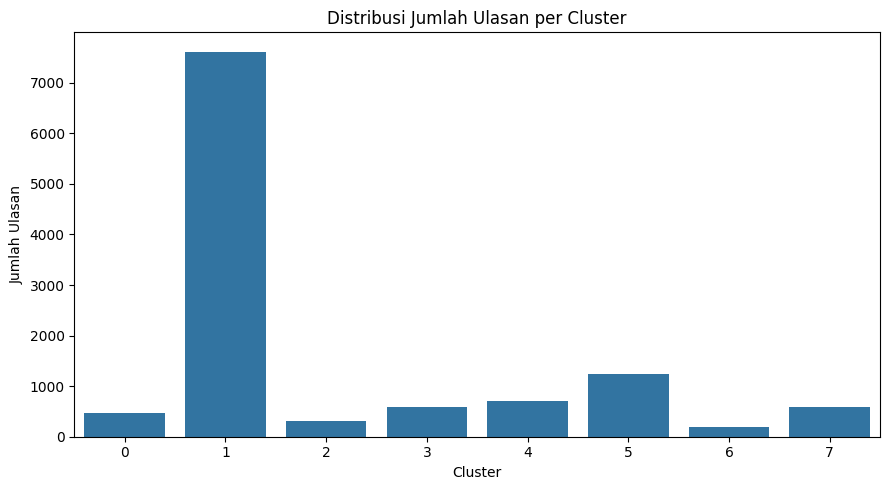

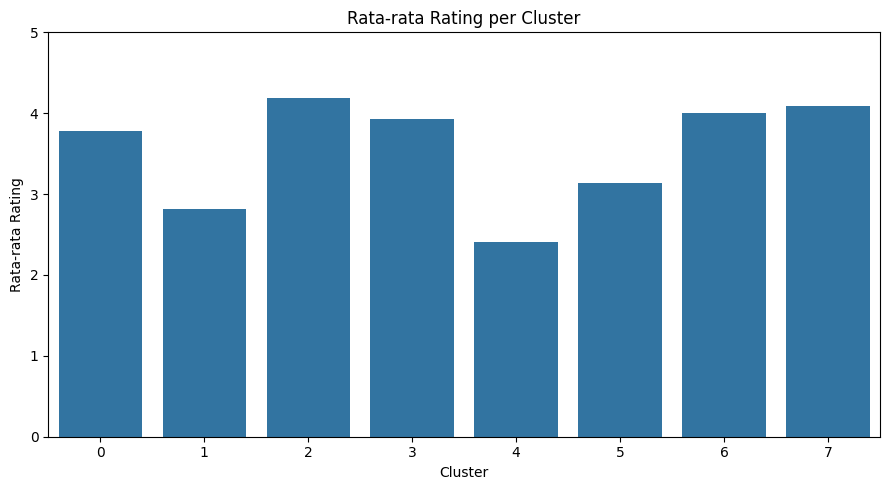

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung ringkasan cluster
ringkasan = df_clean.groupby('cluster_tfidf_b8').agg(
    jumlah_ulasan=('content', 'count'),
    rata_rata_rating=('score', 'mean')
).reset_index()

# Visualisasi 1: jumlah ulasan per cluster
plt.figure(figsize=(9, 5))
sns.barplot(
    data=ringkasan,
    x='cluster_tfidf_b8',
    y='jumlah_ulasan'
)
plt.title('Distribusi Jumlah Ulasan per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Jumlah Ulasan')
plt.tight_layout()
plt.show()

# Visualisasi 2: rata-rata rating per cluster
plt.figure(figsize=(9, 5))
sns.barplot(
    data=ringkasan,
    x='cluster_tfidf_b8',
    y='rata_rata_rating'
)
plt.title('Rata-rata Rating per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Rata-rata Rating')
plt.ylim(0, 5)
plt.tight_layout()
plt.show()


In [15]:

# Menyimpan hasil clustering ke file CSV
kolom_hasil = [
    'content',
    'score',
    'appId',
    'cluster_tfidf_b8'
]

hasil_akhir = df_clean[kolom_hasil].copy()

hasil_akhir.to_csv(
    'hasil_eksperimen_tfidf_b8.csv',
    index=False
)

print("File hasil_eksperimen_tfidf_b8.csv berhasil disimpan.")

# Menyimpan ringkasan cluster
ringkasan.to_csv(
    'ringkasan_tfidf_b8.csv',
    index=False
)

print("File ringkasan_tfidf_b8.csv berhasil disimpan.")


File hasil_eksperimen_tfidf_b8.csv berhasil disimpan.
File ringkasan_tfidf_b8.csv berhasil disimpan.


## Eksperimen 3 — TF-IDF konfigurasi C

Bagian ini merupakan eksperimen pembanding TF-IDF. Hasilnya bukan model final penelitian.

In [16]:

import pandas as pd
import nltk

from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

nltk.download('stopwords', quiet=True)

# Stopwords bahasa Inggris
stop_words = set(stopwords.words('english'))

# Kata umum yang kurang membantu membedakan topik ulasan
custom_stopwords = {
    'app', 'apps', 'application',
    'use', 'used', 'using', 'really',
    'just', 'like', 'good', 'great',
    'love', 'nice', 'best', 'far',
    'get', 'got', 'one', 'would',
    'could', 'also', 'much', 'well',
    'thing', 'things', 'make', 'made'
}

stop_words.update(custom_stopwords)

# Membuat ulang representasi TF-IDF
vectorizer_fix = TfidfVectorizer(
    stop_words=list(stop_words),
    max_features=15000,
    min_df=5,
    max_df=0.4,
    ngram_range=(1, 2),
    sublinear_tf=True,
    norm='l2'
)

X_fix = vectorizer_fix.fit_transform(
    df_clean['cleaned_content'].fillna('')
)

print("Jumlah ulasan:", X_fix.shape[0])
print("Jumlah fitur:", X_fix.shape[1])
print("TF-IDF berhasil dibuat.")


Jumlah ulasan: 11713
Jumlah fitur: 4875
TF-IDF berhasil dibuat.


In [17]:

hasil_fix = []

for k in range(2, 11):
    print(f"Menguji {k} cluster...")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
        max_iter=300
    )

    labels = model.fit_predict(X_fix)

    score = silhouette_score(
        X_fix,
        labels,
        metric='cosine',
        sample_size=3000,
        random_state=42
    )

    ukuran = pd.Series(labels).value_counts()

    hasil_fix.append({
        'k': k,
        'inertia': model.inertia_,
        'silhouette_cosine': score,
        'cluster_terbesar': ukuran.max(),
        'cluster_terkecil': ukuran.min()
    })

evaluasi_fix = pd.DataFrame(hasil_fix)

display(
    evaluasi_fix.sort_values(
        'silhouette_cosine',
        ascending=False
    ).round(4)
)


Menguji 2 cluster...
Menguji 3 cluster...
Menguji 4 cluster...
Menguji 5 cluster...
Menguji 6 cluster...
Menguji 7 cluster...
Menguji 8 cluster...
Menguji 9 cluster...
Menguji 10 cluster...


,k,inertia,silhouette_cosine,cluster_terbesar,cluster_terkecil
8,10,10854.8710,0.0148,7116,109
7,9,10904.4406,0.0115,6645,140
6,8,10929.9507,0.0109,8252,142
5,7,10954.9740,0.0104,7597,279
4,6,10978.6308,0.0094,7906,312
3,5,11006.7485,0.0084,7894,320
2,4,11043.8316,0.0066,8557,470
1,3,11081.9925,0.0043,10169,714
0,2,11121.4449,0.0033,10836,877


In [18]:

# Eksperimen TF-IDF konfigurasi C dengan 10 cluster (bukan model final laporan)
kmeans_fix10 = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=20,
    max_iter=300
)

# Melatih model dan menyimpan label cluster
df_clean['cluster_fix10'] = kmeans_fix10.fit_predict(X_fix)

# Ringkasan jumlah ulasan dan rata-rata rating
ringkasan_fix10 = df_clean.groupby('cluster_fix10').agg(
    jumlah_ulasan=('content', 'count'),
    rata_rata_rating=('score', 'mean'),
    median_rating=('score', 'median')
).round(2)

print("Ringkasan hasil clustering:")
display(ringkasan_fix10)

# Kata dominan setiap cluster
terms_fix = vectorizer_fix.get_feature_names_out()
order_fix = kmeans_fix10.cluster_centers_.argsort()[:, ::-1]

print("\nKata dominan setiap cluster:")

for i in range(10):
    top_terms = [
        terms_fix[j] for j in order_fix[i, :15]
    ]
    print(f"\nCluster {i}:")
    print(", ".join(top_terms))


Ringkasan hasil clustering:


,jumlah_ulasan,rata_rata_rating,median_rating
cluster_fix10,,,
0,140,4.34,5.0
1,109,4.47,5.0
2,1643,3.05,3.0
3,446,3.60,4.0
4,541,2.56,2.0
5,7116,2.99,3.0
6,250,4.27,4.0
7,679,2.49,2.0
8,143,4.16,5.0



Kata dominan setiap cluster:

Cluster 0:
helpful, easy, super helpful, super, easy helpful, helpful easy, simple, find helpful, thank, day, helpful keep, done, schedule, thanks, daily

Cluster 1:
amazing, keep, thank, tool, helpful, time, experience, organised, team, day, superb, work, give stars, us, stars

Cluster 2:
tasks, task, list, add, day, time, daily, completed, way, option, set, widget, lists, need, see

Cluster 3:
habits, habit, track, track habits, tracking, habit tracker, tracker, new, free, want, need, keep, add, day, premium

Cluster 4:
work, reminders, notifications, time, notification, reminders work, reminder, phone, widget, even, notifications work, set, reminder work, sync, day

Cluster 5:
time, need, premium, phone, working, please, update, works, widget, day, even, simple, awesome, want, features

Cluster 6:
easy, simple easy, simple, works, interface, schedule, intuitive, practical, effective, keep, excellent, easy intuitive, organized, need, easy keep

Cluster 

In [19]:

for i in range(10):
    print(f"\n{'='*15} CLUSTER {i} {'='*15}")

    contoh = df_clean[
        df_clean['cluster_fix10'] == i
    ][['content', 'score']].sample(
        n=min(
            5,
            (df_clean['cluster_fix10'] == i).sum()
        ),
        random_state=42
    )

    for _, row in contoh.iterrows():
        print(f"Rating {row['score']}: {row['content']}\n")



=============== CLUSTER 0 ===============
Rating 4: Its helpful

Rating 5: Helpful for my daily activities notes. Thanks a lot.

Rating 4: Nice app and very helpful

Rating 5: I really love this app. Very clean cut and simple. Very helpful.

Rating 4: Pretty useful and very helpful, but it seems like it's not being developed any further. Could have a lot more great features.


=============== CLUSTER 1 ===============
Rating 2: I really like how amazing it is on my phone. But I'm so disappointed to see that it can't be downloaded or visualized on my new galaxy active watch...

Rating 5: Absolutely amazing app and seriously have nothing bad to say. I wish that we can get more perks as we use the app and its features more to encourage us to mange our time wisely

Rating 5: IT'S AMAZING,IT HELPS ME BE MORE ORGANISED

Rating 5: amazing app for Scheduling

Rating 5: Amazing app!! You can literally modify EVERYTHING into the way you prefer! It's a little complex but with only minutes you ca

## Model utama — Sentence Transformers + K-Means

Embedding dibuat dengan `paraphrase-multilingual-MiniLM-L12-v2`. Evaluasi dilakukan untuk k=2–10; model k=10 dipakai untuk interpretasi tema pada laporan, sedangkan k=4 menjadi pembanding.

In [20]:

!pip -q install sentence-transformers


In [21]:

from sentence_transformers import SentenceTransformer
import numpy as np

# Menggunakan model embedding multibahasa
model_embedding = SentenceTransformer(
    'paraphrase-multilingual-MiniLM-L12-v2'
)

teks_ulasan = (
    df_clean['cleaned_content']
    .fillna('')
    .astype(str)
    .tolist()
)

embeddings = model_embedding.encode(
    teks_ulasan,
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Jumlah ulasan:", len(teks_ulasan))
print("Ukuran embedding:", embeddings.shape)


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/184 [00:00<?, ?it/s]

Jumlah ulasan: 11713
Ukuran embedding: (11713, 384)


In [22]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

hasil_embedding = []

for k in range(2, 11):
    print(f"Menguji {k} cluster...")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
        max_iter=300
    )

    labels = model.fit_predict(embeddings)

    # Cosine silhouette dihitung pada sampel agar lebih efisien
    skor = silhouette_score(
        embeddings,
        labels,
        metric='cosine',
        sample_size=min(3000, len(embeddings)),
        random_state=42
    )

    ukuran_cluster = pd.Series(labels).value_counts()

    hasil_embedding.append({
        'k': k,
        'inertia': model.inertia_,
        'silhouette_cosine': skor,
        'cluster_terbesar': ukuran_cluster.max(),
        'cluster_terkecil': ukuran_cluster.min()
    })

hasil_embedding_df = pd.DataFrame(hasil_embedding)

display(
    hasil_embedding_df.sort_values(
        'silhouette_cosine',
        ascending=False
    ).round(4)
)


Menguji 2 cluster...
Menguji 3 cluster...
Menguji 4 cluster...
Menguji 5 cluster...
Menguji 6 cluster...
Menguji 7 cluster...
Menguji 8 cluster...
Menguji 9 cluster...
Menguji 10 cluster...


,k,inertia,silhouette_cosine,cluster_terbesar,cluster_terkecil
0,2,8282.5830,0.1280,6188,5525
1,3,7920.4336,0.1021,4437,3006
2,4,7657.7310,0.0879,3373,2507
8,10,7016.8140,0.0831,2079,744
7,9,7085.7588,0.0818,2137,772
5,7,7268.1895,0.0778,2292,1118
6,8,7173.1719,0.0755,2155,1008
4,6,7376.6021,0.0754,2413,1494
3,5,7506.1387,0.0753,2623,1924


In [23]:

from sklearn.cluster import KMeans
import pandas as pd

# Membandingkan k=4 dan k=10 pada embedding semantik; k=10 dipakai sebagai model final untuk interpretasi tema
model_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

model_10 = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

df_clean['cluster_semantik_4'] = model_4.fit_predict(embeddings)
df_clean['cluster_semantik_10'] = model_10.fit_predict(embeddings)

# Ringkasan model 4 cluster
print("RINGKASAN 4 CLUSTER")

ringkasan_4 = df_clean.groupby('cluster_semantik_4').agg(
    jumlah_ulasan=('content', 'count'),
    rata_rata_rating=('score', 'mean'),
    median_rating=('score', 'median')
).round(2)

display(ringkasan_4)

# Ringkasan model 10 cluster
print("RINGKASAN 10 CLUSTER")

ringkasan_10 = df_clean.groupby('cluster_semantik_10').agg(
    jumlah_ulasan=('content', 'count'),
    rata_rata_rating=('score', 'mean'),
    median_rating=('score', 'median')
).round(2)

display(ringkasan_10)

# Contoh ulasan acak dari setiap cluster
for kolom, jumlah_cluster in [
    ('cluster_semantik_4', 4),
    ('cluster_semantik_10', 10)
]:
    print(f"\n{'='*45}")
    print(f"CONTOH ULASAN: {jumlah_cluster} CLUSTER")
    print('='*45)

    for i in range(jumlah_cluster):
        bagian = df_clean[df_clean[kolom] == i]

        contoh = bagian.sample(
            n=min(8, len(bagian)),
            random_state=42
        )

        print(f"\n--- CLUSTER {i} ({len(bagian)} ulasan) ---")

        for _, row in contoh.iterrows():
            teks = str(row['content']).replace('\n', ' ')
            print(f"Rating {row['score']}: {teks[:300]}")


RINGKASAN 4 CLUSTER


,jumlah_ulasan,rata_rata_rating,median_rating
cluster_semantik_4,,,
0,2925,2.92,3.0
1,2908,3.95,4.0
2,3373,2.01,2.0
3,2507,3.48,4.0


RINGKASAN 10 CLUSTER


,jumlah_ulasan,rata_rata_rating,median_rating
cluster_semantik_10,,,
0,964,2.43,2.0
1,1658,2.11,2.0
2,929,2.42,2.0
3,1304,3.02,3.0
4,1207,4.18,4.0
5,1048,1.90,2.0
6,771,2.41,2.0
7,744,4.02,4.0
8,2079,4.20,4.0



CONTOH ULASAN: 4 CLUSTER

--- CLUSTER 0 (2925 ulasan) ---
Rating 4: Great honestly great way to keep track of daily tasks to stay organized. One thing they should add is overall goals. And tasks leading to those goals.
Rating 2: lately been worse. latest updates have been making things worse. like when you edit the time for the event, the new way to do it is absolutely terrible and least user friendly way to select times. it was perfect and smooth before idk what changed. also no response from support for weeks now about bu
Rating 3: I can't arrange my habits in the order I want. I have to choose from preselected options like alphabetical.
Rating 3: Love this app Please add a option to Remind me every day At a specific time that I choose. "Remind me every day option" Sometimes I repeat some task daily so I don't need to create them again and again there is option repeat the task daily but it there is no option to "remind Daily"
Rating 2: Need Wifi/Data for it. I get that you can play 

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# Samakan indeks DataFrame agar berurutan
df_clean = df_clean.reset_index(drop=True)

# Buat ulang matriks TF-IDF
vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5
)

X_tfidf = vectorizer.fit_transform(
    df_clean["content"].fillna("")
)

terms = vectorizer.get_feature_names_out()

# Cari kata kunci setiap cluster
for i in range(10):
    subset = df_clean[
        df_clean["cluster_semantik_10"] == i
    ]

    if len(subset) == 0:
        continue

    # Indeks sekarang sesuai dengan posisi baris matriks
    X_cluster = X_tfidf[subset.index]

    mean_scores = X_cluster.mean(axis=0).A1
    top_indices = mean_scores.argsort()[-10:][::-1]

    print(f"\nCLUSTER {i} ({len(subset)} ulasan)")
    print("Kata kunci:", ", ".join(terms[top_indices]))


CLUSTER 0 (964 ulasan)
Kata kunci: bad, ads, good, pay, just, complicated, confusing, like, don, time

CLUSTER 1 (1658 ulasan)
Kata kunci: app, phone, just, use, time, update, like, good, great, work

CLUSTER 2 (929 ulasan)
Kata kunci: version, free, premium, pro, app, pro version, free version, pay, paid, features

CLUSTER 3 (1304 ulasan)
Kata kunci: tasks, task, list, app, time, day, add, like, lists, set

CLUSTER 4 (1207 ulasan)
Kata kunci: easy, use, easy use, good, simple, helpful, great, helps, useful, love

CLUSTER 5 (1048 ulasan)
Kata kunci: account, work, working, sync, doesn, sign, login, email, use, widget

CLUSTER 6 (771 ulasan)
Kata kunci: notifications, notification, reminders, reminder, alarm, app, work, sound, set, don

CLUSTER 7 (744 ulasan)
Kata kunci: good, great, nice, love, amazing, best, helpful, far, awesome, like

CLUSTER 8 (2079 ulasan)
Kata kunci: app, great, good, love, great app, good app, really, best, nice, like

CLUSTER 9 (1009 ulasan)
Kata kunci: calend

In [25]:
ringkasan_final = (
    df_clean.groupby("cluster_semantik_10")
    .agg(
        jumlah_ulasan=("content", "count"),
        rata_rata_rating=("score", "mean"),
        median_rating=("score", "median"),
        rating_1_2=("score", lambda x: (x <= 2).mean() * 100),
        rating_4_5=("score", lambda x: (x >= 4).mean() * 100)
    )
    .round(2)
)

ringkasan_final.columns = [
    "Jumlah Ulasan",
    "Rata-rata Rating",
    "Median Rating",
    "Rating 1-2 (%)",
    "Rating 4-5 (%)"
]

display(ringkasan_final)

,Jumlah Ulasan,Rata-rata Rating,Median Rating,Rating 1-2 (%),Rating 4-5 (%)
cluster_semantik_10,,,,,
0,964,2.43,2.0,56.74,23.44
1,1658,2.11,2.0,68.64,13.21
2,929,2.42,2.0,58.56,21.74
3,1304,3.02,3.0,37.96,41.33
4,1207,4.18,4.0,7.04,82.44
5,1048,1.90,2.0,75.95,11.35
6,771,2.41,2.0,55.51,18.55
7,744,4.02,4.0,13.44,75.40
8,2079,4.20,4.0,8.03,81.67


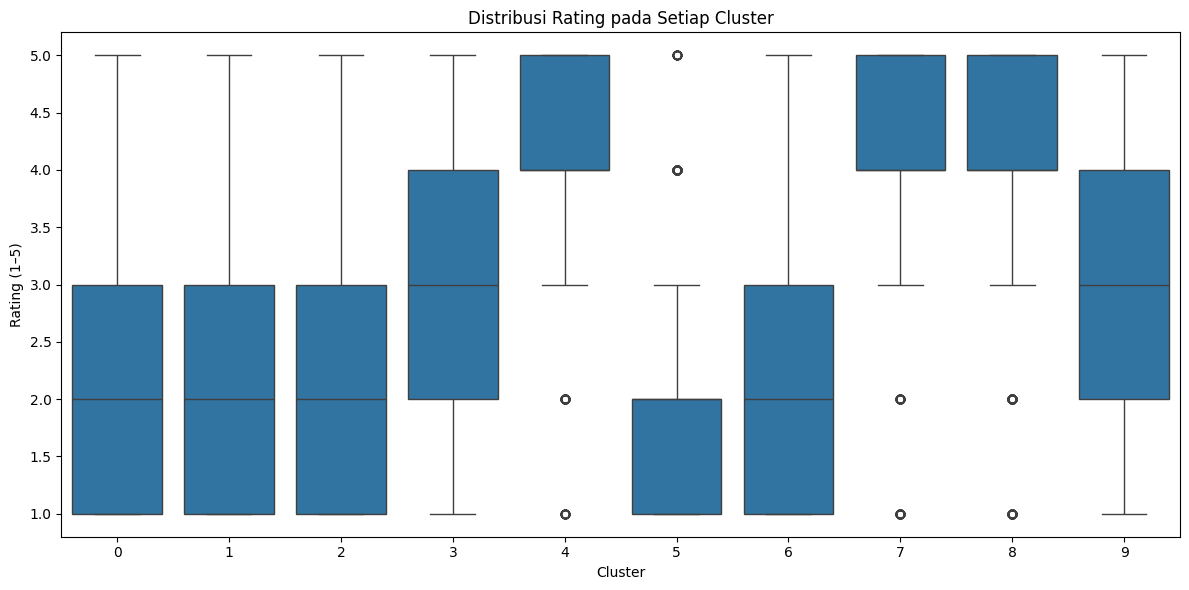

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_clean,
    x="cluster_semantik_10",
    y="score"
)

plt.title("Distribusi Rating pada Setiap Cluster")
plt.xlabel("Cluster")
plt.ylabel("Rating (1–5)")
plt.tight_layout()
plt.show()

In [27]:
df_clean.to_csv(
    "hasil_clustering_semantik_k10.csv",
    index=False,
    encoding="utf-8-sig"
)

print("File berhasil disimpan: hasil_clustering_semantik_k10.csv")

File berhasil disimpan: hasil_clustering_semantik_k10.csv
